
=== SV Count (PDO) Summary ===
Total samples: 35
Max SVs per sample: 348.0
Mean SVs per sample: 85.91
Min SVs per sample: 3.0
Total SVs (all samples): 3,007


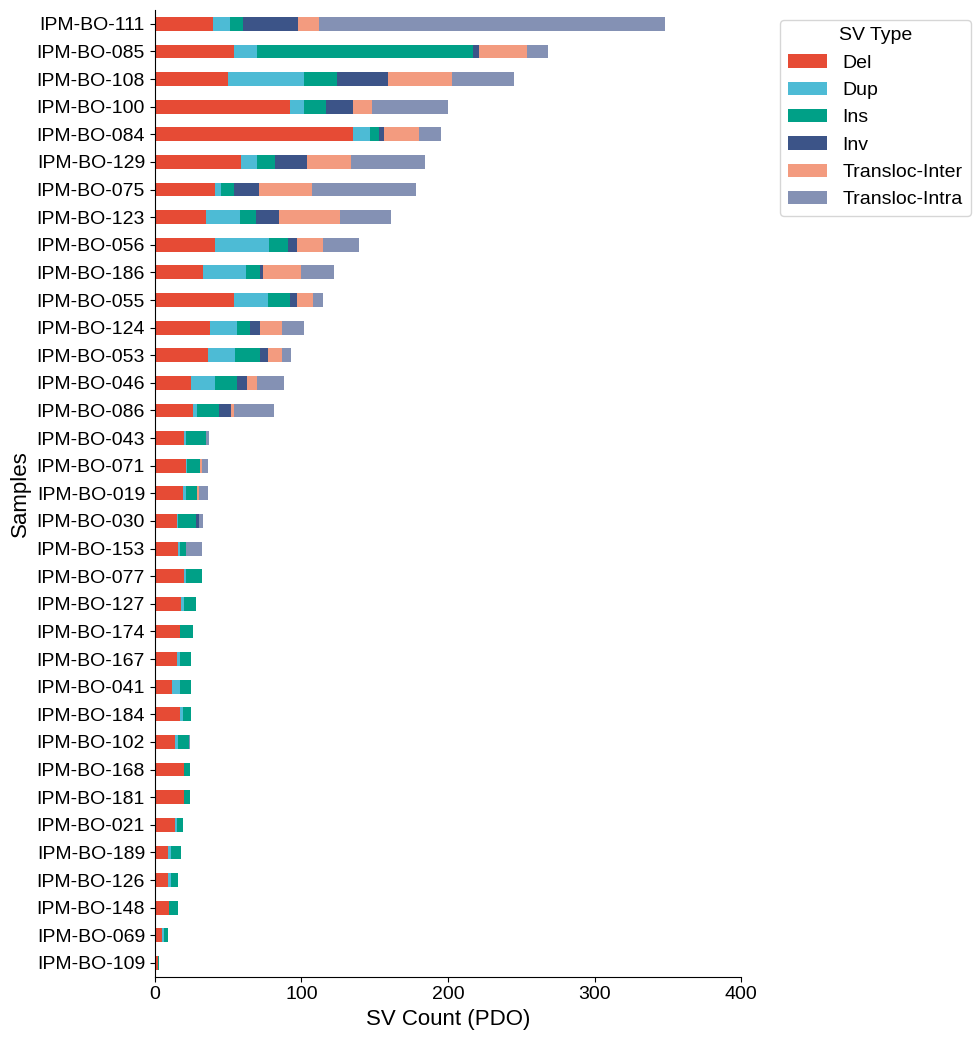


=== SV Count (Tumor) Summary ===
Total samples: 27
Max SVs per sample: 595.0
Mean SVs per sample: 83.00
Min SVs per sample: 7.0
Total SVs (all samples): 2,241


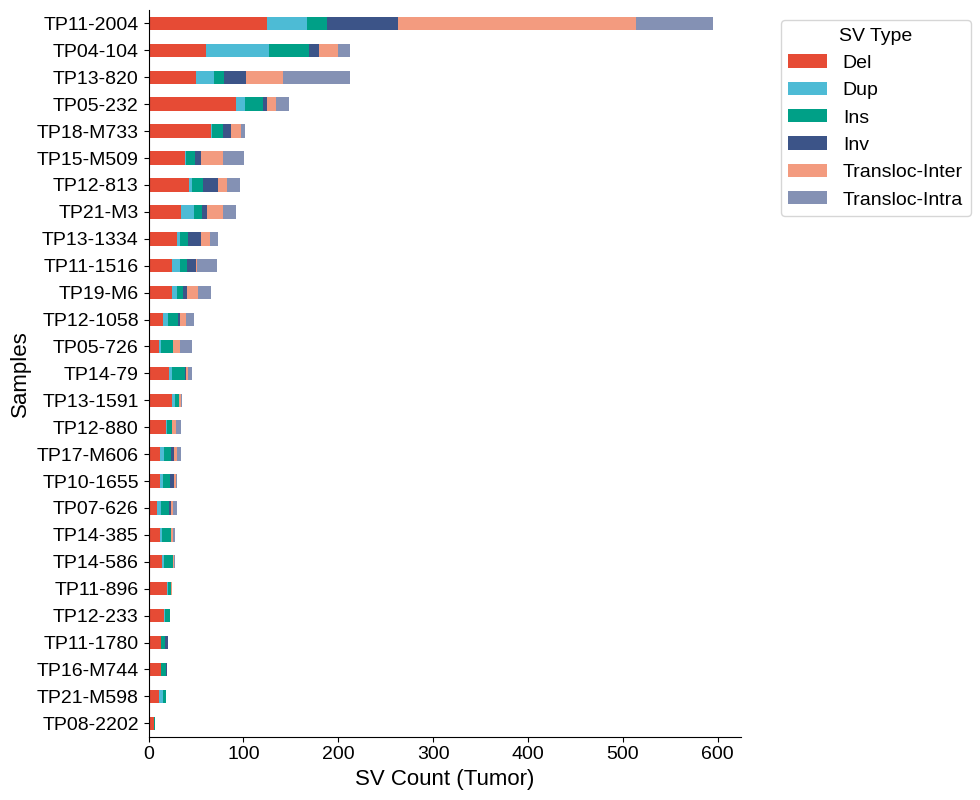

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl

# =============================
# CONFIG
# =============================
file_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_unqiue.csv"
sample_col = "sample"
type_col = "Type"

# === COLOR MAP FOR SV TYPES ===
type_colors = {
    "Del": "#E64B35",
    "Dup": "#4DBBD5",
    "Ins": "#00A087",
    "Inv": "#3C5488",
    "Transloc-Inter": "#F39B7F",
    "Transloc-Intra": "#8491B4",
}

# Fixed order of SV types
sv_order = ["Del", "Dup", "Ins", "Inv", "Transloc-Inter", "Transloc-Intra"]

# =============================
# LOAD AND CLEAN
# =============================
df = pd.read_csv(file_path, low_memory=False)
df.columns = [col.strip().replace('\r', '') for col in df.columns]
df = df[[sample_col, type_col]].dropna()

df[sample_col] = df[sample_col].astype(str).str.strip()
df[type_col] = df[type_col].astype(str).str.strip()

df = df[df[type_col].isin(type_colors.keys())]

# =============================
# SPLIT PDO vs TUMOR
# =============================
pdo_df = df[df[sample_col].str.startswith("IPM")].copy()
tumor_df = df[df[sample_col].str.startswith("TP")].copy()

# =============================
# FUNCTION TO COMPUTE STATS + PLOT
# =============================
def plot_sv_count_barplot(data, x_label, output_file):
    if data.empty:
        print(f"No data found for {x_label}")
        return

    # Count SVs by sample and type
    sv_counts = data.groupby([sample_col, type_col]).size().reset_index(name="Count")

    # Pivot for stacked bar layout
    sv_pivot = sv_counts.pivot(index=sample_col, columns=type_col, values="Count").fillna(0)

    # Keep SV types in fixed order
    sv_pivot = sv_pivot.reindex(columns=sv_order, fill_value=0)

    # Total SV count per sample
    sv_pivot["Total"] = sv_pivot.sum(axis=1)

    # ===== Print summary =====
    print(f"\n=== {x_label} Summary ===")
    print(f"Total samples: {len(sv_pivot)}")
    print(f"Max SVs per sample: {sv_pivot['Total'].max():,}")
    print(f"Mean SVs per sample: {sv_pivot['Total'].mean():.2f}")
    print(f"Min SVs per sample: {sv_pivot['Total'].min():,}")
    print(f"Total SVs (all samples): {int(sv_pivot['Total'].sum()):,}")

    # ===== Sort samples by total count =====
    sv_pivot = sv_pivot.sort_values("Total", ascending=True)
    sv_pivot_no_total = sv_pivot.drop(columns="Total")

    # ===== Plot =====
    ax = sv_pivot_no_total.plot(
        kind="barh",
        stacked=True,
        figsize=(10, max(6, len(sv_pivot_no_total) * 0.3)),
        color=[type_colors[t] for t in sv_pivot_no_total.columns]
    )

    ax.set_xlabel(x_label, fontsize=16)
    ax.set_ylabel("Samples", fontsize=16)
    ax.tick_params(axis="y", labelsize=14)
    ax.tick_params(axis="x", labelsize=14)

    ax.legend(
        title="SV Type",
        bbox_to_anchor=(1.05, 1),
        loc="upper left",
        fontsize=14,
        title_fontsize=14
    )

    # X-axis tick interval every 100
    ax.set_xticks(range(0, int(sv_pivot["Total"].max()) + 100, 100))

    # Remove top and right spines
    sns.despine(top=True, right=True)

    plt.tight_layout()
    plt.savefig(output_file, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

# =============================
# FOR PDO AND TUMOR
# =============================
plot_sv_count_barplot(
    pdo_df,
    "SV Count (PDO)",
    "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_Count_perSample_PDO.pdf"
)

plot_sv_count_barplot(
    tumor_df,
    "SV Count (Tumor)",
    "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_Count_perSample_Tumor.pdf"
)

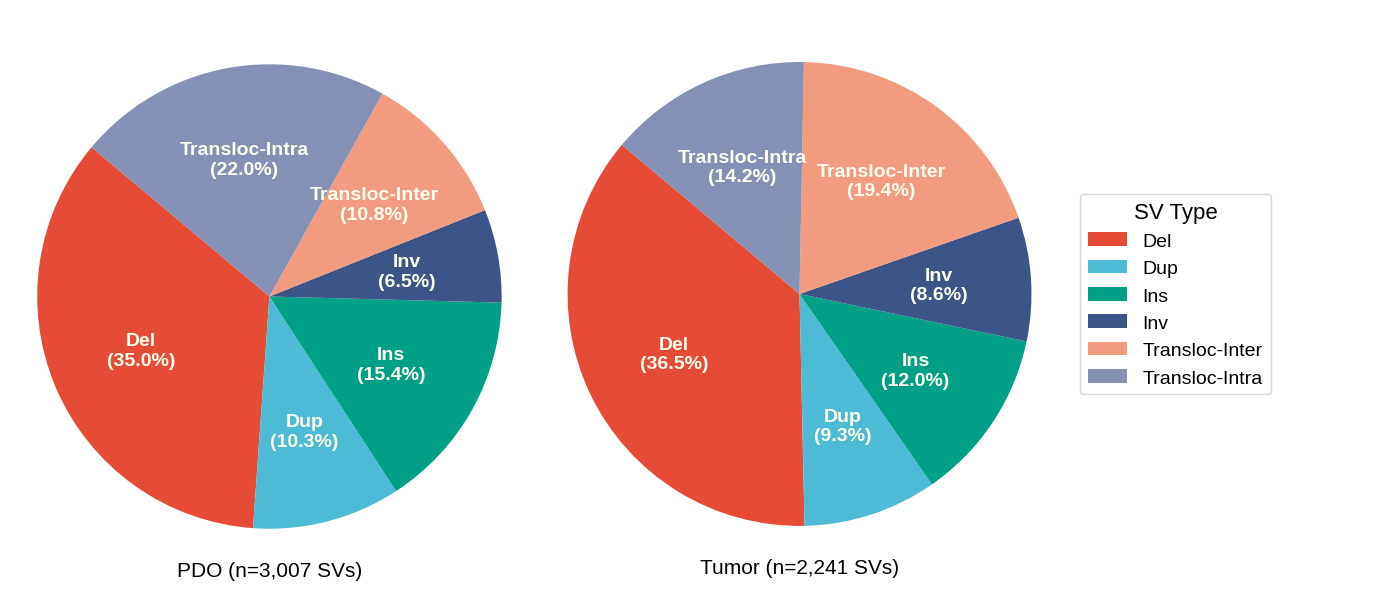

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# === CONFIG ===
file_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_unqiue.csv"
sample_col = "sample"
type_col = "Type"

# === COLOR MAP FOR SV TYPES ===
type_colors = {
    "Del": "#E64B35",
    "Dup": "#4DBBD5",
    "Ins": "#00A087",
    "Inv": "#3C5488",
    "Transloc-Inter": "#F39B7F",
    "Transloc-Intra": "#8491B4",
}

# === OPTIONAL DISPLAY LABELS ===
type_display = {
    "Del": "Del",
    "Dup": "Dup",
    "Ins": "Ins",
    "Inv": "Inv",
    "Transloc-Inter": "Transloc-Inter",
    "Transloc-Intra": "Transloc-Intra",
}

# === LOAD DATA ===
df = pd.read_csv(file_path, low_memory=False)
df.columns = [col.strip().replace('\r', '') for col in df.columns]
df = df[[sample_col, type_col]].dropna()
df[sample_col] = df[sample_col].astype(str).str.strip()
df[type_col] = df[type_col].astype(str).str.strip()
df = df[df[type_col].isin(type_colors.keys())]

# === SPLIT INTO PDO AND TUMOR ===
pdo_df = df[df[sample_col].str.startswith("IPM")].copy()
tumor_df = df[df[sample_col].str.startswith("TP")].copy()

# === FUNCTION: GENERIC PIE ===
def make_pie(ax, data_counts, label):
    total = data_counts.sum()

    wedges, texts = ax.pie(
        data_counts,
        labels=None,
        colors=[type_colors[k] for k in data_counts.index],
        startangle=140
    )

    # Add inside labels manually with type and percentage
    for w, (t, v) in zip(wedges, data_counts.items()):
        if v == 0:
            continue

        ang = (w.theta2 + w.theta1) / 2
        x = 0.6 * np.cos(np.deg2rad(ang))
        y = 0.6 * np.sin(np.deg2rad(ang))
        pct = v / total * 100 if total > 0 else 0

        ax.text(
            x, y,
            f"{type_display.get(t, t)}\n({pct:.1f}%)",
            ha="center",
            va="center",
            fontsize=14,
            color="#FFFFF0",
            fontweight="bold"
        )

    ax.text(
        0, -1.18,
        f"{label} (n={total:,} SVs)",
        ha="center",
        va="center",
        fontsize=15
    )

    ax.axis("equal")
    return ax

# === FUNCTION: MAIN PLOT ===
def plot_type_piecharts(pdo_df, tumor_df, output_prefix):
    pdo_counts = pdo_df[type_col].value_counts().reindex(type_colors.keys(), fill_value=0)
    tumor_counts = tumor_df[type_col].value_counts().reindex(type_colors.keys(), fill_value=0)

    # --- COMBINED FIGURE ---
    fig, axes = plt.subplots(
        1, 3,
        figsize=(14, 6),
        gridspec_kw={"width_ratios": [1, 1, 0.6]}
    )

    make_pie(axes[0], pdo_counts, "PDO")
    make_pie(axes[1], tumor_counts, "Tumor")

    # --- LEGEND PANEL ---
    legend_handles = [Patch(facecolor=type_colors[t], label=type_display.get(t, t)) for t in type_colors]
    axes[2].legend(
        handles=legend_handles,
        loc="center left",
        fontsize=14,
        title="SV Type",
        title_fontsize=16
    )
    axes[2].axis("off")

    plt.tight_layout()
    plt.savefig(f"{output_prefix}_combined.pdf", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

# === RUN ===
plot_type_piecharts(
    pdo_df,
    tumor_df,
    "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_type_distribution"
)

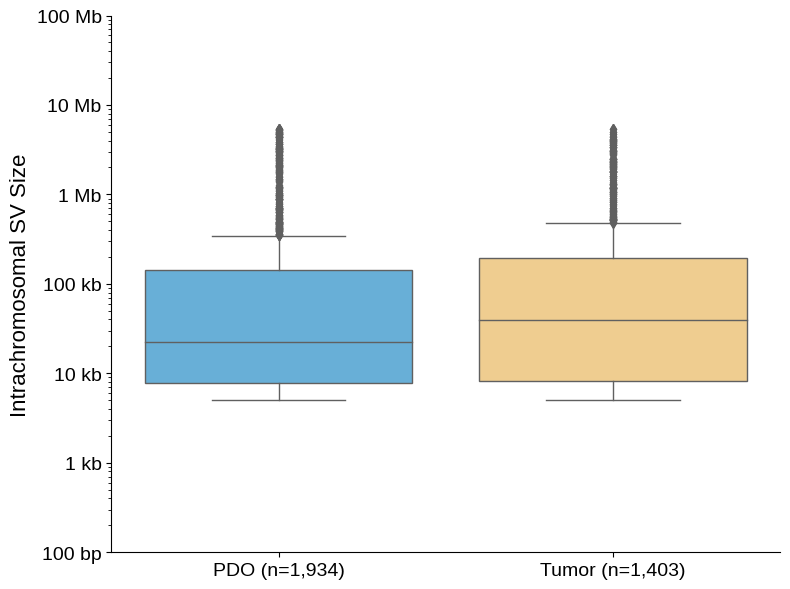

In [37]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# === CONFIG ===
file_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_unqiue.csv"
sample_col = "sample"
ref1_col = "RefcontigID1"
ref2_col = "RefcontigID2"
size_col = "SVsize"

# === LOAD AND CLEAN DATA ===
df = pd.read_csv(file_path, low_memory=False)
df.columns = [col.strip().replace('\r', '') for col in df.columns]

# === FILTER INTRACHROMOSOMAL SVs ===
df = df[df[ref1_col] == df[ref2_col]]
df = df[[sample_col, size_col]].dropna()
df[size_col] = pd.to_numeric(df[size_col], errors='coerce')
df = df[df[size_col] > 0]

# === LABEL GROUPS ===
df['Group'] = df[sample_col].apply(
    lambda s: 'PDO' if str(s).startswith("IPM") else 'Tumor' if str(s).startswith("TP") else None
)
df = df[df['Group'].notna()]

# === COUNT PER GROUP ===
group_counts = df['Group'].value_counts()
pdo_label = f"PDO (n={group_counts.get('PDO', 0):,})"
tumor_label = f"Tumor (n={group_counts.get('Tumor', 0):,})"

# === PLOT ===
plt.figure(figsize=(8, 6))
sns.boxplot(
    data=df,
    x='Group',
    y=size_col,
    palette=["#56B4E9", "#FFD180"],  # Blue for PDO, Peachy-pale orange for Tumor
    linewidth=1
)


plt.yscale('log')
plt.yticks(
    ticks=[1e2, 1e3, 1e4, 1e5, 1e6, 1e7, 1e8],
    labels=["100 bp", "1 kb", "10 kb", "100 kb", "1 Mb", "10 Mb", "100 Mb"],
    fontsize=14
)
plt.ylabel("Intrachromosomal SV Size", fontsize=16)
plt.xlabel("")
plt.xticks([0, 1], [pdo_label, tumor_label], fontsize=14)

# === Remove box and extra axes ===
sns.despine(top=True, right=True)

plt.tight_layout()
plt.savefig("/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_intrachromosomal_SV_size_boxplot.pdf", dpi=300)
plt.show()


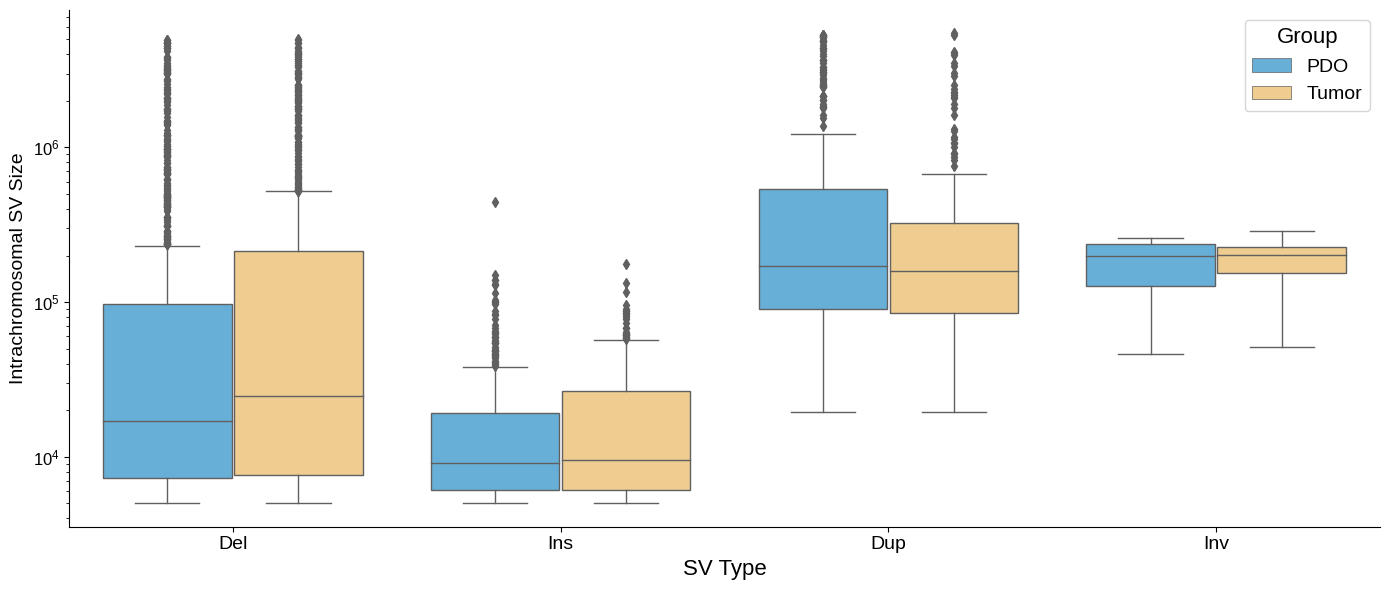

  SV Type  PDO n  Tumor n  U Statistic   p-value
0     Del   1052      817     393215.5  0.001599
2     Dup    310      209      35572.0  0.057991
1     Ins    463      270      60346.5  0.435151
3     Inv    109      107       5863.0  0.946182


In [38]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# === CONFIG ===
file_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_unqiue.csv"
sample_col = "sample"
ref1_col = "RefcontigID1"
ref2_col = "RefcontigID2"
size_col = "SVsize"
sv_type_col = "Type"

# === LOAD AND CLEAN DATA ===
df = pd.read_csv(file_path, low_memory=False)
df.columns = [col.strip().replace('\r', '') for col in df.columns]

# === BASIC CLEANING ===
df = df[
    (df[ref1_col] == df[ref2_col])  # Intrachromosomal only
][[sample_col, size_col, ref1_col, ref2_col, sv_type_col]].dropna()

df[size_col] = pd.to_numeric(df[size_col], errors='coerce')
df = df[df[size_col] > 0]

# === LABEL GROUPS ===
df['Group'] = df[sample_col].apply(
    lambda s: 'PDO' if str(s).startswith("IPM") else 'Tumor' if str(s).startswith("TP") else None
)
df = df[df['Group'].notna()]

# === SV Size by Type and Group ===
plt.figure(figsize=(14, 6))
sns.boxplot(
    data=df,
    x=sv_type_col,
    y=size_col,
    hue='Group',
    palette=["#56B4E9", "#FFD180"],  # Blue for PDO, Peachy-orange for Tumor
    linewidth=1
)

plt.yscale('log')
plt.ylabel("Intrachromosomal SV Size", fontsize=14)
plt.xlabel("SV Type", fontsize=16)
plt.xticks(rotation=0, fontsize=14)
plt.yticks(fontsize=12)
plt.legend(title='Group', fontsize=14, title_fontsize=16)
sns.despine(top=True, right=True) # Remove top and right axes
plt.tight_layout()
plt.savefig("/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/intrachr_sv_size_by_type_and_group_boxplot.pdf", dpi=300)
plt.show()

from scipy.stats import mannwhitneyu
import pandas as pd

results = []

# Loop through each SV type
for sv_type in df[sv_type_col].dropna().unique():
    subset = df[df[sv_type_col] == sv_type]
    pdo_sizes = subset[subset['Group'] == 'PDO'][size_col].dropna()
    tumor_sizes = subset[subset['Group'] == 'Tumor'][size_col].dropna()
    
    # Proceed only if both groups have data
    if len(pdo_sizes) > 0 and len(tumor_sizes) > 0:
        stat, p = mannwhitneyu(pdo_sizes, tumor_sizes, alternative='two-sided')
        results.append((sv_type, len(pdo_sizes), len(tumor_sizes), stat, p))

# Convert to DataFrame and display
results_df = pd.DataFrame(results, columns=["SV Type", "PDO n", "Tumor n", "U Statistic", "p-value"])
results_df.sort_values("p-value", inplace=True)
print(results_df)


Splitting data...
Processing Chr1...
Processing Chr10...
Processing Chr11...
Processing Chr12...
Processing Chr13...
Processing Chr14...
Processing Chr15...
Processing Chr16...
Processing Chr17...
Processing Chr18...
Processing Chr19...
Processing Chr2...
Processing Chr20...
Processing Chr21...
Processing Chr22...
Processing Chr3...
Processing Chr4...
Processing Chr5...
Processing Chr6...
Processing Chr7...
Processing Chr8...
Processing Chr9...
Processing ChrX...
Processing Chr1...
Processing Chr10...
Processing Chr11...
Processing Chr12...
Processing Chr13...
Processing Chr14...
Processing Chr15...
Processing Chr16...
Processing Chr17...
Processing Chr18...
Processing Chr19...
Processing Chr2...
Processing Chr20...
Processing Chr21...
Processing Chr22...
Processing Chr3...
Processing Chr4...
Processing Chr5...
Processing Chr6...
Processing Chr7...
Processing Chr8...
Processing Chr9...
Processing ChrX...


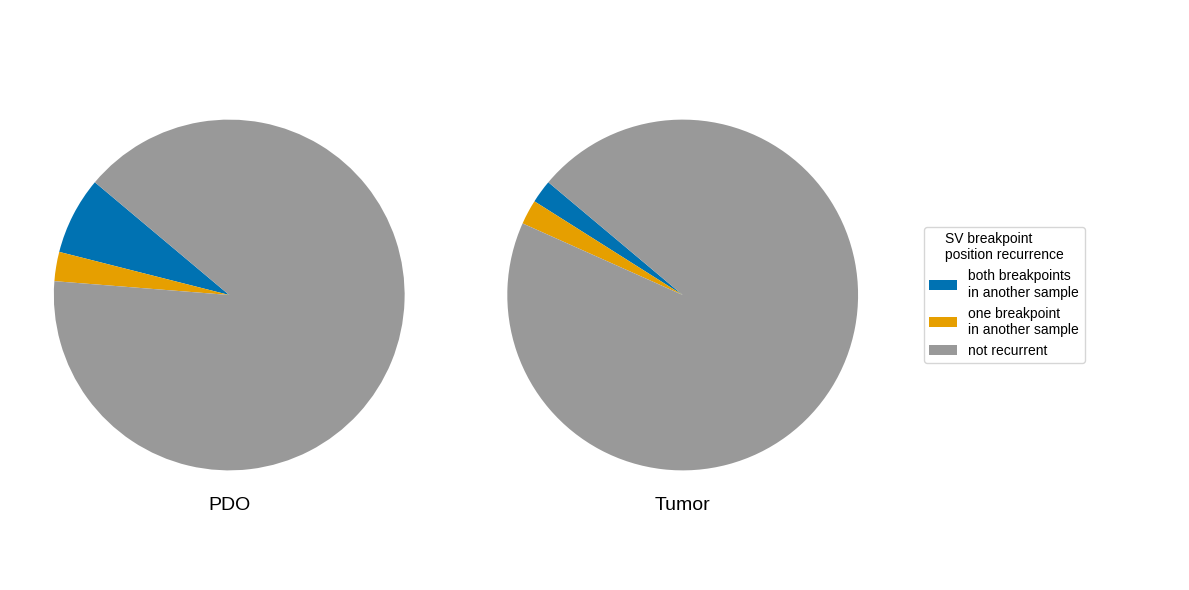

Most Common Breakpoints - PDO
Most Common Breakpoints:
        Chr  RefStartPos  RefEndPos  Count
72     Chr1     83171695   83186312      3
2529   Chr8     15919069   15931293      3
1740  Chr21     10326071   10330635      3
1703  Chr20     16681624   16694271      3
198    Chr1    208273500  208285657      3
131    Chr1    144173283  144201874      3
2541   Chr8     34961278   35006991      2
132    Chr1    144764512  144793096      2
2060   Chr4    157184404  157247892      2
1918   Chr3    145332002   42732769      2
Most Common Breakpoints - Tumor
Most Common Breakpoints:
        Chr  RefStartPos  RefEndPos  Count
921   Chr19     46520475   46523206      5
1490   Chr5     14993191   15008321      3
924   Chr19     49015337   49065744      3
355   Chr11    130564635  130569929      2
1174   Chr3      9315206    9329155      2
2035   Chr8     69945525   69956979      2
50     Chr1     49550727   49568265      2
116    Chr1    144136462  144154890      2
1361   Chr3    186701501  18

In [48]:
# Breakpoint proximity with a tolerance of ±1000 bp
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# === CONFIG ===
file_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_unqiue.csv"
chr_col = "Chr"
start_col = "RefStartPos"
end_col = "RefEndPos"
sample_col = "sample"

# === COLORS AND LEGEND LABELS ===
colors = {
    "Both breakpoints recurrent": "#0072B2",  # Blue
    "One breakpoint recurrent": "#E69F00",    # Orange
    "Not recurrent": "#999999",               # Grey
}

legend_labels = {
    "Both breakpoints recurrent": "both breakpoints\nin another sample",
    "One breakpoint recurrent": "one breakpoint\nin another sample",
    "Not recurrent": "not recurrent"
}

# === LOAD AND CLEAN DATA ===
df = pd.read_csv(file_path, low_memory=False)
df.columns = [col.strip().replace('\r', '') for col in df.columns]
df = df[[chr_col, start_col, end_col, sample_col]].dropna()

# Apply deduplication to ensure no data duplication
# This step will prevent multiple entries of the same SV record from being counted more than once
df = df.drop_duplicates(subset=[chr_col, start_col, end_col, sample_col])

df[start_col] = pd.to_numeric(df[start_col], errors='coerce')
df[end_col] = pd.to_numeric(df[end_col], errors='coerce')
df = df.dropna()

# === SPLIT DATA INTO PDO AND TUMOR ===
print("Splitting data...")
pdo_df = df[df[sample_col].str.startswith("IPM", na=False)].copy()
tumor_df = df[df[sample_col].str.startswith("TP", na=False)].copy()

# === RECURRING CLASSIFICATION FUNCTION ===

# Allowable slop for breakpoint matching
slop = 1000

# Updated recurrence classification function
# SV class is not considered; only breakpoints are checked

def classify_recurrence(df_subset):
    def single_row_classify(row, group_df):
        sample = row[sample_col]
        chr_ = row[chr_col]
        start = row[start_col]
        end = row[end_col]
        others = group_df[(group_df[sample_col] != sample) & (group_df[chr_col] == chr_)]

        # Check for start and end matches in any SV in another sample (class-independent)
        both_rec = others[((others[start_col] >= start - slop) & (others[start_col] <= start + slop)) &
                          ((others[end_col] >= end - slop) & (others[end_col] <= end + slop))]

        # Check for start or end matches independently
        start_rec = others[(others[start_col] >= start - slop) & (others[start_col] <= start + slop)]
        end_rec = others[(others[end_col] >= end - slop) & (others[end_col] <= end + slop)]

        if len(both_rec) > 0:
            return "Both breakpoints recurrent"
        elif len(start_rec) > 0 or len(end_rec) > 0:
            return "One breakpoint recurrent"
        else:
            return "Not recurrent"

    # Apply the classification for each chromosome group
    recurrence_results = []
    for chrom, group in df_subset.groupby(chr_col):
        print(f"Processing {chrom}...")
        rec = group.apply(lambda row: single_row_classify(row, group), axis=1)
        recurrence_results.append(rec)

    return pd.concat(recurrence_results)


# === CLASSIFY RECURRENCE ===
pdo_df['Recurrence'] = classify_recurrence(pdo_df)
tumor_df['Recurrence'] = classify_recurrence(tumor_df)

# === SAVE RESULTS TO CSV ===
pdo_df.to_csv("/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/PDO_SV_breakpoint_recurrence.csv", index=False)
tumor_df.to_csv("/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/Tumor_SV_breakpoint_recurrence.csv", index=False)

# === FILTER TO 3 TARGET CLASSES ONLY FOR PLOTTING ===
valid_classes = list(colors.keys())
pdo_df = pdo_df[pdo_df['Recurrence'].isin(valid_classes)]
tumor_df = tumor_df[tumor_df['Recurrence'].isin(valid_classes)]

# === PLOTTING FUNCTION ===
def plot_recurrence_comparison(pdo_df, tumor_df, output_file):
    pdo_counts = pdo_df['Recurrence'].value_counts().reindex(valid_classes, fill_value=0)
    tumor_counts = tumor_df['Recurrence'].value_counts().reindex(valid_classes, fill_value=0)

    fig, axes = plt.subplots(1, 3, figsize=(12, 6), gridspec_kw={'width_ratios': [1, 1, 0.6]})

    # --- PDO pie chart ---
    wedges1 = axes[0].pie(
        pdo_counts,
        labels=None,
        colors=[colors[k] for k in pdo_counts.index],
        startangle=140
    )
    axes[0].text(0, -1.2, "PDO", 
                 ha='center', va='center', fontsize=14)

    # --- Tumor pie chart ---
    wedges2 = axes[1].pie(
        tumor_counts,
        labels=None,
        colors=[colors[k] for k in tumor_counts.index],
        startangle=140
    )
    axes[1].text(0, -1.2, "Tumor", 
                 ha='center', va='center', fontsize=14)

    # --- Legend ---
    legend_handles = [
        Patch(facecolor=colors[k], label=legend_labels[k]) for k in valid_classes
    ]
    axes[2].legend(
        handles=legend_handles,
        loc='center left',
        fontsize=10,
        title="SV breakpoint\nposition recurrence"
    )
    axes[2].axis('off')

    plt.tight_layout()
    plt.savefig(output_file, dpi=300)
    plt.show()

# === RUN FINAL PLOT ===
plot_recurrence_comparison(
    pdo_df,
    tumor_df,
    "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_SV_recurrence_PDO_vs_Tumor_piechart.pdf"
)

# === IDENTIFY MOST COMMON BREAKPOINT ===
def identify_most_common_breakpoint(df):
    breakpoint_counts = df.groupby([chr_col, start_col, end_col]).size().reset_index(name='Count')
    most_common = breakpoint_counts.sort_values(by='Count', ascending=False).head(10)
    print("Most Common Breakpoints:")
    print(most_common)
    return most_common

# Identify most common breakpoints for PDO and Tumor
print("Most Common Breakpoints - PDO")
most_common_pdo = identify_most_common_breakpoint(pdo_df)

print("Most Common Breakpoints - Tumor")
most_common_tumor = identify_most_common_breakpoint(tumor_df)
